## Семинар 12. Снижение размерности, кластеризация

### О семинаре

В этом семинаре мы:

- Изучим, зачем нужно понижать размерность данных

- Посмотрим на различные способы это сделать

- Посмотрим, как зависит работа разных кластеризаций от различных параметров

- Будем находить торговые центры в Москве с помощью кластеризации

In [1]:
import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt

import plotly.io as pio
import matplotlib_inline

sns.set(style="ticks", context="talk")
plt.style.use("dark_background")
pio.templates.default = pio.templates.merge_templates("plotly_dark", "presentation")
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg')

pd.set_option('display.max_columns', None)

## План

### Изменение размерности входных данных

Общий смысл всех преобразований:
* Перевести $d$ признаков в $k<d$ признаков так, чтобы информация об исходных различиях и прочих зависимостях между объектами сохранилась как можно лучше.

Применения:

* Отображение $d$ признаков в 2 (реже - в 3) для возможности визуализации данных
* Уменьшение размерности $d$ -> $k<d$ для увеличения скорости обучения модели
* Уменьшение размерности $d$ -> $k<d$ для увеличения качества обученной модели

#### PCA (Principal Component Analysis, Метод главных компонент)


Более подробную мат. базу вы пройдете лекциях, а тут приведем интуитивную логику работы данного алгоритма

Пусть мы хотим найти такое отображение из $d$-мерного пространства в $k$-мерное, которое наилучшим образом сохранит "различаемость" наших объектов.

In [2]:
from IPython.display import Image

Image(url='https://www.pvsm.ru/images/2019/09/18/Must-have-algoritmy-mashinnogo-obucheniya.png')



Например, в случае отображения 2d в 1d хочется избежать такой ситуации:

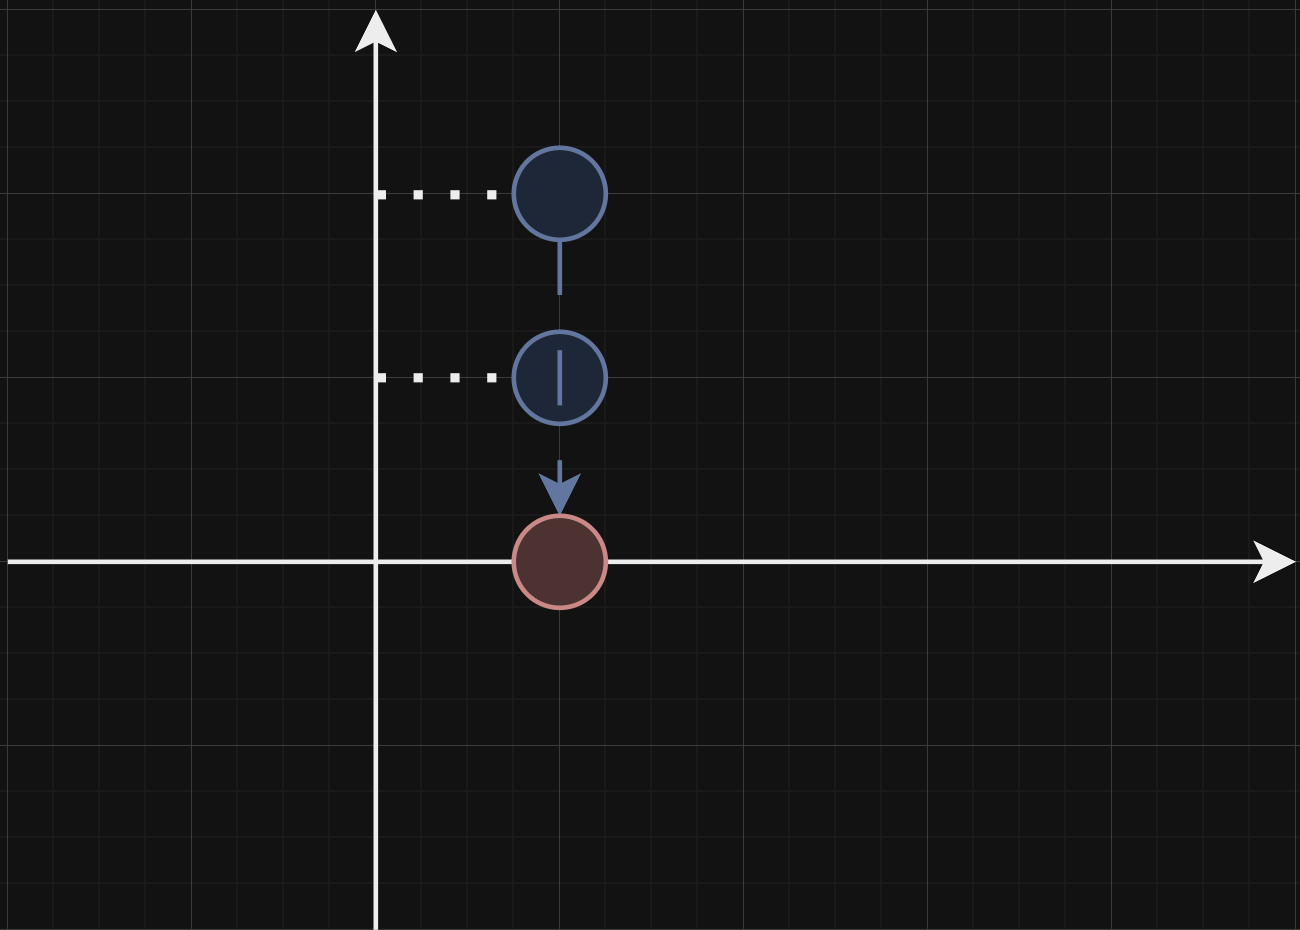

В приведенном выше примере мы перестали различать 2 объекта, так как новый 1 признак у них стал одним и тем же. Из такого плохого примера можно вывести общую идею PCA:

<font color='green'>**Идея:**</font> При проекции в $k$-мерное пространство нужно сделать так, чтобы дисперсия признака по каждому базису (осей) была максимально возможной - то есть чтобы было как можно меньше ситуаций, когда признаки становятся менее различимыми

Эту идею хорошо иллюстрирует гифка ниже:

In [6]:
Image(url='https://i.stack.imgur.com/Q7HIP.gif')

Бонусом можно заметить, что когда на линии красные точки распределены максимально широко, то сумма длин красных перпендикуляров на эту линию минимальна. То есть, мы проецируем наши данные в новое пространство с "минимальной ошибкой". Это не простое совпадение, а строго доказываемый математический факт, который, на самом деле, следует из способа поиска данного наилучшего $k$-мерного подпростнаства.

<font color='orange'> **Важно!** </font>

* Перед применением PCA необходимо отнормировать признаки - иначе будет сильная зависимость величины дисперсии от порядка величины признаков. Тем не менее, при использовании разреженных признаков (таких как tf-idf) нормировать признаки необязательно, так как они уже сами по себе фактически являются нормированными

* Выбросы тоже могут влиять на информативность применения PCA, поэтому их тоже можно проанализировать и удалить

##### Смотрим визуализацию

Давайте попробуем посмотреть, как отработает PCA на примере датасета iris

In [7]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

iris = load_iris()

X = iris.data
y = iris.target
target_names = iris.target_names

In [8]:
X.shape, iris.feature_names

((150, 4),
 ['sepal length (cm)',
  'sepal width (cm)',
  'petal length (cm)',
  'petal width (cm)'])

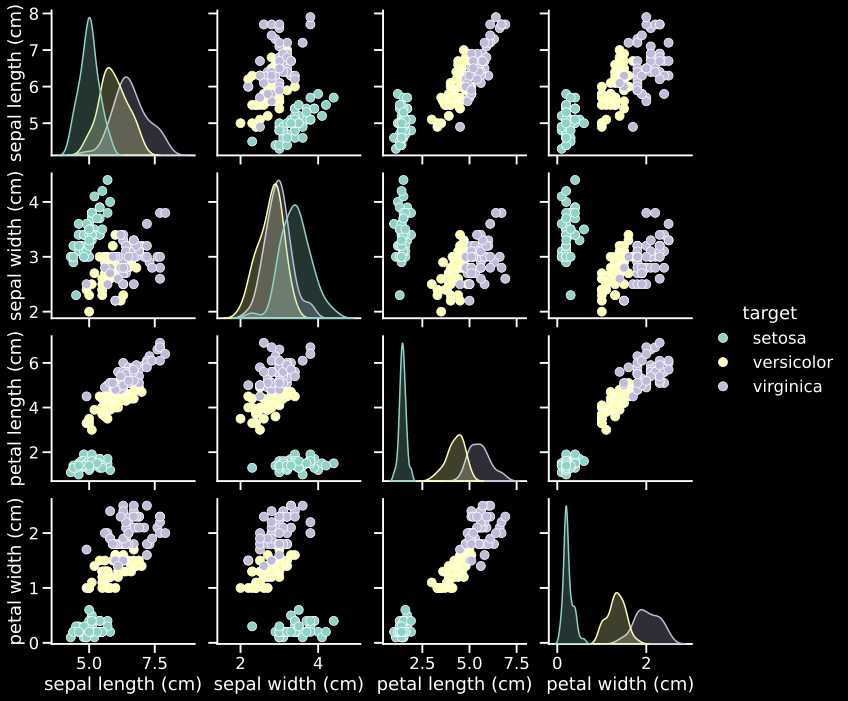

In [9]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["target"] = target_names[y]
sns.pairplot(df, hue="target")

В целом ясно видно, что каждому классу соответствует свое облачко "кластера". Давайте проверим, сохранятся ли они в случае проекций.

Сначала отнормируем данные:

In [10]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [11]:
# X_scaled = StandardScaler().fit_transform(X)
X_scaled = MinMaxScaler().fit_transform(X)

В одномерное пространство:

In [12]:
pca = PCA(n_components=1)

# X_transformed = pca.fit_transform(X_scaled)
pca.fit(X_scaled)
X_transformed = pca.transform(X_scaled)

X_transformed.shape

(150, 1)

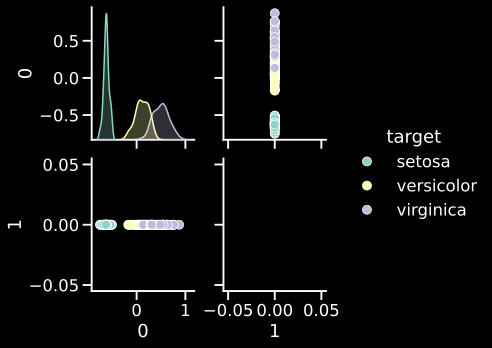

In [13]:
df = pd.DataFrame(X_transformed)
df["1"] = 0
df["target"] = target_names[y]
sns.pairplot(df, hue="target")

В двумерное пространство

In [14]:
pca = PCA(n_components=2)

X_transformed = pca.fit_transform(X_scaled)

X_transformed.shape

(150, 2)

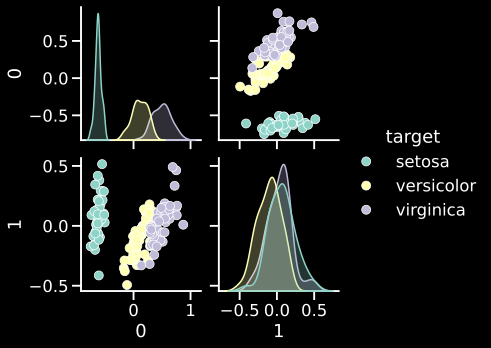

In [15]:
df = pd.DataFrame(X_transformed)
df["target"] = target_names[y]
sns.pairplot(df, hue="target")

В трехмерное пространство

In [16]:
pca = PCA(n_components=3)

X_transformed = pca.fit_transform(X_scaled)

X_transformed.shape

(150, 3)

In [17]:
df = pd.DataFrame(X_transformed)
df["target"] = target_names[y]
fig=px.scatter_3d(data_frame=df, x=0, y=1, z=2, color='target')
fig.update_traces(marker=dict(size=10,
                              line=dict(width=3,
                                        color='white')))

На самом деле, проекции на какую-либо из осей пытаются приблизить изначальную дисперсию в данных. Поэтому можем нарисовать график того, сколько компонент нужно для такого, чтобы "восстановить" изначальную дисперсию:

<font color='red'> **Pro tip:** </font> На самом деле разброс по каждой из осей это *собственные значения* $S$ - матрицы ковариации $X$, соответствующие этим осям (которые являются *собственными векторами* этой же матрицы $S$)

In [18]:
pca = PCA()
pca.fit(X_scaled)

df = pd.DataFrame()
df["n_components"] = np.arange(1, pca.n_components_ + 1).astype(int)
df["explained_variance_ratio"] = np.cumsum(pca.explained_variance_ratio_)

px.line(df, x='n_components', y='explained_variance_ratio')

<font color='orange'> **Внезапный вопрос:** </font> секундочку, а где же главные компоненты, в честь которых называется метод?

На самом деле главные компоненты в общем-то и есть направления тех осей, на которые мы проецировали наши данные. Давайте попробуем их отобразить на примере других данных:

In [19]:
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces(shuffle=True, random_state=432542)
faces_images = faces.data
faces_ids = faces.target
image_shape = (64, 64)

faces_images.shape

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data


(400, 4096)

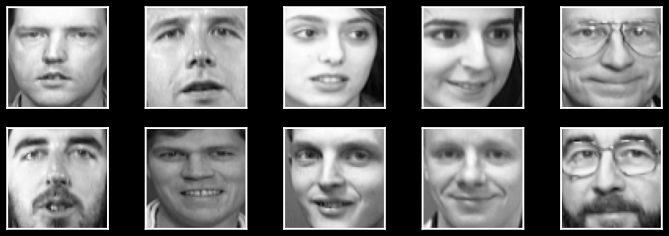

In [20]:
rows = 2
cols = 5

n_samples = rows * cols

plt.figure(figsize=(12, 4))
for i in range(n_samples):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(faces_images[i, :].reshape(image_shape), cmap='gray')
    plt.xticks(())
    plt.yticks(())

plt.show()

Изобразим среднее лицо:

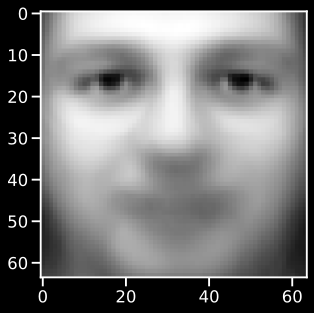

In [21]:
plt.imshow(faces_images.mean(axis=0).reshape(image_shape), cmap='gray')

// Найдите 10 отличий

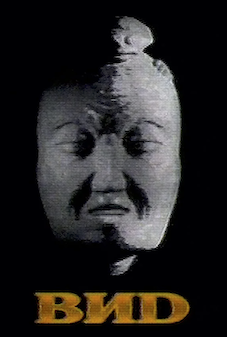

In [22]:
faces_normalized = faces_images - faces_images.mean(axis=0)

pca = PCA()
pca.fit(faces_normalized)

PCA()

Изобразим главные компоненты, по уменьшению их вклада в разброс

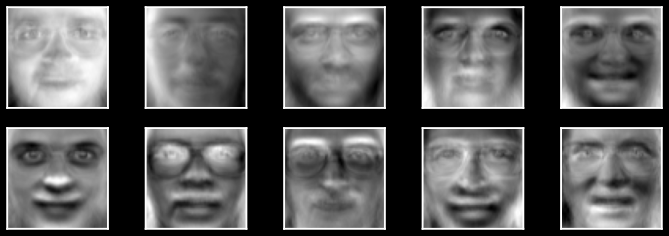

In [23]:
rows = 2
cols = 5

n_samples = rows * cols

plt.figure(figsize=(12, 4))
for i in range(n_samples):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(pca.components_[i, :].reshape(image_shape), cmap='gray')
    plt.xticks(())
    plt.yticks(())

plt.show()

Посмотрим, какой вклад в долю описываемого разброса вносят компоненты:

In [ ]:
df = pd.DataFrame()
df["n_components"] = np.arange(1, pca.n_components_ + 1).astype(int)
df["explained_variance_ratio"] = np.cumsum(pca.explained_variance_ratio_)

px.line(df, x='n_components', y='explained_variance_ratio')

На самом деле, умея проецировать данные на подпространство размерности $k$, мы умеем и процировать данные обратно в пространство размерности $d$, например, зануляя размерности $>k$ и поворачивая точки в соответствии с направлениями найденных компонент. Это можно считать аппроксимацией исходного объекта с помощью подпростарнства размерности $k$ (т.е. используя $k$ главных компонент)

Такой трюк помогает сократить и расходы на хранение информации - например (на графике выше), сжимая информацию с 4096 признаков до 150 (и сохраняя >96% explained_variance), мы теперь храним матрицы размером 400x150 + 150 векторов размера 4096. Это вместо матрицы 400x4096. Сжали информацию более чем в 2,5 раза!

Посмотрим, как картинки восстанавливаются в зависимости от разного числа $k$:

In [24]:
df = pd.DataFrame()
faces = []
compress = []
ks = []

for compress_percent in np.linspace(0, 1, 10):
    k = int(faces_normalized.shape[0] * compress_percent)
    pca = PCA(n_components=k)
    pca.fit(faces_normalized)

    faces_compressed = pca.transform(faces_normalized)
    faces_restored = pca.inverse_transform(faces_compressed) + np.mean(faces_images, axis=0)

    faces.append(faces_restored[1, :])
    compress.append(compress_percent)
    ks.append(k)

df["faces"] = faces
df["compress_percent"] = compress
df["k"] = ks

In [25]:
fig = go.Figure()

for _, x in df.iterrows():
    fig.add_trace(go.Heatmap(z=x["faces"].reshape(image_shape), showscale=False, colorscale='gray'))

for n in range(1, len(fig.data)):
    fig.data[n].visible = False
fig.data[0].visible = True

steps = []
for i in range(len(fig.data)):
    step = dict(
        method = 'restyle',
        args = ['visible', [False] * len(fig.data)],
        label=str(df.iloc[i, :]["k"])
    )
    step['args'][1][0] = True
    step['args'][1][i] = True
    steps.append(step)

sliders = [dict(
    active=0,
    steps=steps,
    currentvalue={"prefix": "K= ", "suffix": " components"},
)]

fig.update_yaxes(autorange='reversed', scaleanchor='x', constrain='domain')
fig.update_xaxes(constrain='domain')

fig.layout.sliders = sliders
fig.show()

##### Плюсы, минусы, применимость, источники

<font color='green'> **Плюсы:** </font>
* Позволяет уменьшить переобучение в многомерных данных
* Уменьшает скоррелированность признаков
* Эффективнее по времени работает на больших данных, чем некоторые другие более сложные методы уменьшения размерности
* Можно использовать с дефолтными гиперпараметрами (помимо `n_components`), настройка далеко не всегда нужна
* Детерминированный

<font color='red'> **Минусы:** </font>
* Может ловить только линейные зависимости между объектами
* Новое пространство признаков не особо интерпретируемо

<font color='lightblue'> **Область применимости:** </font>
* Стандартизированные данные
* По возможности без аномалий и выбросов


<font color='orange'> **Pro tip!** </font>
* Более подробно с математической точки зрения про PCA будет на Advanced-лекции. Ссылки на почитать:
    * [Лекция про PCA](https://github.com/victorkitov/ML/blob/main/150-PCA.pdff)
    * [Интуитивный рассказ про PCA](https://stats.stackexchange.com/questions/2691/making-sense-of-principal-component-analysis-eigenvectors-eigenvalues/140579#140579)

* [kernelPCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.KernelPCA.html) - для снижения размерности с учетом нелинейных зависимостей
    * [Небольшое объяснение](https://www.geeksforgeeks.org/ml-introduction-to-kernel-pca/)

#### TSNE (t-distributed Stochastic Neighbor Embedding)

<font color='green'> **Идея:** </font> Давайте пытаться сохранить не "глобально" хорошую дисперсию по признакам, а локальные свойства объектов. То есть сделать так, чтобы похожие объекты, которые находятся локально близко друг от друга, оставались таковыми и в новом пространстве. Заодно попытаемся таким образом и нелинейную зависимость в данных сохранить

Данная идея реализуется за счет того, что можно посчитать вероятности близости объектов в исходном и новом пространстве и минимизировать расстояние между полученными расределениями.

##### Смотрим визуализацию

Посмотрим, как справится PCA и TSNE на примере датасета digits

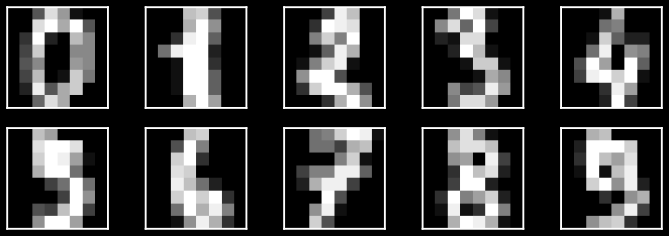

In [26]:
from sklearn.datasets import load_digits
digits = load_digits()

X = digits.data
y = digits.target

image_shape = (8, 8)
rows = 2
cols = 5

n_samples = rows * cols

plt.figure(figsize=(12, 4))
for i in range(n_samples):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(X[i, :].reshape(image_shape), cmap='gray')
    plt.xticks(())
    plt.yticks(())

plt.show()

In [27]:
X.shape, np.unique(y)

((1797, 64), array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]))

In [28]:
X_scaled = StandardScaler().fit_transform(X)

In [34]:
X_scaled.shape

(1797, 64)

In [29]:
pca = PCA(n_components=3)
X_transformed = pca.fit_transform(X_scaled)

df = pd.DataFrame(X_transformed)
df["target"] = y.astype(int)
fig=px.scatter_3d(data_frame=df, x=0, y=1, z=2, color='target')
fig.update_traces(marker=dict(size=10,
                              line=dict(width=3,
                                        color='white')))

In [30]:
pca = PCA(n_components=2)
X_transformed = pca.fit_transform(X_scaled)

df = pd.DataFrame(X_transformed)
df["target"] = y.astype(int)
fig=px.scatter(data_frame=df, x=0, y=1, color='target')
fig.update_traces(marker=dict(size=10,
                              line=dict(width=1,
                                        color='white')))

In [31]:
from sklearn.manifold import TSNE

In [32]:
tsne = TSNE(n_components=3)
X_transformed = tsne.fit_transform(X_scaled)

df = pd.DataFrame(X_transformed)
df["target"] = y.astype(int)
fig=px.scatter_3d(data_frame=df, x=0, y=1, z=2, color='target')
fig.update_traces(marker=dict(size=10,
                              line=dict(width=3,
                                        color='white')))

In [ ]:
tsne = TSNE(n_components=2)
X_transformed = tsne.fit_transform(X_scaled)

df = pd.DataFrame(X_transformed)
df["target"] = y.astype(int)
fig=px.scatter(data_frame=df, x=0, y=1, color='target')
fig.update_traces(marker=dict(size=10,
                              line=dict(width=1,
                                        color='white')))

Один из важных параметров этого метода - `perplexity` - контролирует, как много точек считать "соседними". В зависимости от этого параметра визуализация может разительно отличаться

In [35]:
# Будет работать долго, не запускайте

import tqdm

digits_arrays = []
perplexities = [1, 3, 5, 10, 20, 30, 40, 50]

for perplexity in tqdm.tqdm(perplexities):
    tsne = TSNE(n_components=2, perplexity=perplexity)
    tsne.fit(X_scaled)

    digits_arrays.append(tsne.fit_transform(X_scaled))

 62%|██████▎   | 5/8 [02:37<01:34, 31.42s/it]


KeyboardInterrupt: 

In [ ]:
fig = go.Figure()

for x in digits_arrays:
    df = pd.DataFrame(x)
    df["target"] = y.astype(int)
    fig.add_traces(list(px.scatter(data_frame=df, x=0, y=1, color='target').select_traces()))

for n in range(1, len(fig.data)):
    fig.data[n].visible = False
fig.data[0].visible = True

steps = []
for i in range(len(fig.data)):
    step = dict(
        method = 'restyle',
        args = ['visible', [False] * len(fig.data)],
        label=str(perplexities[i])
    )
    step['args'][1][i] = True
    steps.append(step)

sliders = [dict(
    active=1,
    steps=steps,
    currentvalue={"prefix": "Perplexity= ", "suffix": ""},
)]

fig.update_yaxes(autorange='reversed', scaleanchor='x', constrain='domain')
fig.update_xaxes(constrain='domain')

fig.layout.sliders = sliders
fig.show()

##### Плюсы, минусы, применимость, источники

<font color='green'> **Плюсы:** </font>
* Сохраняет локальную структуру близости объектов
* Умеет находить и сохранять нелинейные зависимости

<font color='red'> **Минусы:** </font>
* Долго работает, рекомендуется для больших размерностей сначала применять PCA (чтобы уменьшить число признаков хотя бы до 50)
* Не отображает действительную форму кластеров, не отображает действительное расстояние между кластерами
* Новое пространство признаков не особо интерпретируемо
* Недетерминированный

<font color='lightblue'> **Область применимости:** </font>
* Данные должны быть стандартизированы (но центрировать их не обязательно).
* На небольших данных. При необходимости использовать ускоренные версии алгоритма
* Нет метода `transform:` нельзя сначала "обучить" модель, а потом ее "применять" к другим данным
* Рекомендуется использовать `perplexity` в диапазоне [5, 50]

<font color='orange'> **Pro tip!** </font>
* Полезные ссылки:
    * [Визуализация работы tsne](https://distill.pub/2016/misread-tsne/)
    * [Про tsne](https://www.blog.dailydoseofds.com/p/how-to-avoid-getting-misled-bay-t)
    * [Библиотека Multicore-TSNE с ускоренным TSNE](https://github.com/DmitryUlyanov/Multicore-TSNE)


#### UMAP (Uniform Manifold Approximation and Projection)

Придумано в 2018 году. Совмещает в себе скорость PCA, сохранение локальной структуры от TSNE, старается сохранить и глобальную структуру

##### Смотрим визуализацию

In [36]:
!pip install umap-learn

In [ ]:
from umap import UMAP

In [ ]:
umap = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric='euclidean')
umap.fit(X_scaled)
X_transformed = umap.transform(X_scaled)

df = pd.DataFrame(X_transformed)
df["target"] = y.astype(int)
fig=px.scatter(data_frame=df, x=0, y=1, color='target')
fig.update_traces(marker=dict(size=10,
                              line=dict(width=1,
                                        color='white')))

##### Плюсы, минусы, применимость, источники

<font color='green'> **Плюсы:** </font>
* Пытается сохранить и локальную структуру и глобальную, есть степень контроля этого
* Больше остальных методов подходит для задач кластеризации за счет попытки сохранения сходства между кластерами

<font color='red'> **Минусы:** </font>
* Не sklearn
* Может требовать много RAM
* Недетерминированный
* Много гиперпараметров для настройки

<font color='lightblue'> **Область применимости:** </font>
* Стандартизированные данные
* Можно применять на больших данных

<font color='orange'> **Pro tip!** </font>
* [Сравнение UMAP, tSNE, PCA](https://evogeek.ru/articles/264055/)
* [Обзор UMAP 1](https://habr.com/ru/companies/skillfactory/articles/580154/)
* [Обзор UMAP 2](https://habr.com/ru/companies/newprolab/articles/350584/)
* [Особенности UMAP для кластеризации](https://umap-learn.readthedocs.io/en/latest/clustering.html)

#### IsoMap (Isometric Mapping)

Идея алгоритма заключается в построении графа ближайших соседей и вычисления кратчайшего пути между парами точек (фактически геодезическое расстояние). Далее применение строится на основе алгоритма [MDS (Multidimensional scaling)](https://scikit-learn.org/stable/modules/manifold.html#multidimensional-scaling)

##### Смотрим визуализацию

In [ ]:
from sklearn.manifold import Isomap

In [ ]:
isomap = Isomap(n_neighbors=5, n_components=2)
isomap.fit(X_scaled)
X_transformed = isomap.transform(X_scaled)

df = pd.DataFrame(X_transformed)
df["target"] = y.astype(int)
fig=px.scatter(data_frame=df, x=0, y=1, color='target')
fig.update_traces(marker=dict(size=10,
                              line=dict(width=1,
                                        color='white')))

##### Плюсы, минусы, применимость, источники

<font color='green'> **Плюсы:** </font>
* Хорошо отображает взаимоположение объектов из-за подсчета геодезического расстояния
* Сохраняет и глобальную, и локальную структуру
* Учитывает нелинейность данных


<font color='red'> **Минусы:** </font>
* Небыстрый
* Несколько параметров для настройки

<font color='lightblue'> **Область применимости:** </font>
* Стандартизированные данные
* Желательно очистить данные от шумов и аномалий

<font color='orange'> **Pro tip!** </font>
* [Гид по IsoMap](https://medium.com/@conniezhou678/unraveling-data-patterns-with-isomap-a-guide-to-dimensionality-reduction-part-4-1d774eee69a5)
* [Алгоритм IsoMap](https://thegreedychoice.github.io/machinelearning/isomap)
* [MDS](https://www.geeksforgeeks.org/multidimensional-scaling-mds-using-scikit-learn/)


### Кластеризация

Теперь, умея визуализировать высокоразмерные данные, наконец-то перейдем к практике с различными кластеризациями

#### Kmeans

Немного визуала :)

In [ ]:
import numpy as np
import pandas as pd

from IPython.display import HTML, display
import ipywidgets as widgets
from ipywidgets import interact
import networkx as nx

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.datasets import make_blobs, make_moons, load_digits

import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
from matplotlib.animation import FuncAnimation
from matplotlib.lines import Line2D
from IPython.display import HTML, display
import ipywidgets as widgets
from ipywidgets import interact
import networkx as nx

sns.set_style('whitegrid')
COLORMAP = 'Spectral'

In [ ]:
X_blobs, y_blobs = make_blobs(n_samples=500, centers=4, cluster_std=0.6, random_state=42)

In [ ]:
# Функция для визуализации результатов
def plot_clustering_results(datasets, titles, suptitle, centroids=None, legend_loc='upper right', scatter_size=40):
    """ Строит сетку с результатами кластеризации """
    n_plots = len(datasets)
    fig, axes = plt.subplots(1, n_plots, figsize=(8 * n_plots, 7))
    if n_plots == 1:
        axes = [axes]

    for i, (ax, title) in enumerate(zip(axes, titles)):
        X, y_pred = datasets[i]

        unique_labels = np.unique(y_pred)
        has_noise = -1 in unique_labels
        n_clusters = len(unique_labels) - (1 if has_noise else 0)
        subtitle = f'{title}\n(Найдено кластеров: {n_clusters})'

        # Палитра
        palette = plt.get_cmap(COLORMAP)
        rgba_colors = palette(np.linspace(0, 1, max(1, n_clusters)))
        cluster_labels = sorted([l for l in unique_labels if l >= 0])
        color_map = {label: rgba_colors[i] for i, label in enumerate(cluster_labels)}
        point_colors = [color_map[label] if label != -1 else (0.85, 0.85, 0.85) for label in y_pred]

        # Объекты
        ax.scatter(X[:, 0], X[:, 1], c=point_colors, s=scatter_size, alpha=0.9)

        # Для отрисовки легенды
        legend_handles = []

        # Отрисовка центроидов (для k-Means)
        if centroids is not None:
            ax.scatter(centroids[:, 0], centroids[:, 1], c='black', s=40, marker='X')
            legend_handles.append(Line2D([0], [0], marker='X', color='none',
                                         markeredgecolor='black', markerfacecolor='black',
                                         label='Центроиды', markersize=8))

        # Метки классов
        for label in cluster_labels:
            legend_handles.append(Line2D([0], [0], marker='o', color='w',
                                         label=f'Кластер {label}',
                                         markerfacecolor=color_map[label], markersize=10))
        # Шум
        if has_noise:
            legend_handles.append(Line2D([0], [0], marker='o', color='w', label='Шум',
                                         markerfacecolor=(0.85, 0.85, 0.85), markersize=10))

        ax.legend(handles=legend_handles, loc=legend_loc)

        ax.set_title(subtitle, fontsize=16)
        ax.set_xticks([])
        ax.set_yticks([])
        sns.despine(ax=ax, left=True, bottom=True)

    fig.suptitle(suptitle, fontsize=20, y=1.02)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [ ]:
def plot_kmeans_interactive(k=4):
    """ Функция для визуализации результата работы k-Means """
    model = KMeans(n_clusters=k, random_state=42, n_init='auto')

    y_pred = model.fit_predict(X_blobs)
    centroids = model.cluster_centers_

    plot_clustering_results(
        [(X_blobs, y_pred)],
        [''],
        f'Интерактивный подбор k для k-Means',
        centroids
    )

# Добавим слайдер, который привяжем к нашей функции визуализации

k_slider = widgets.IntSlider(
    min=1, max=10, step=1, value=4,
    description='Число кластеров (k):',
    continuous_update=False,
    style={'description_width': 'initial'},
    layout={'width': '500px'}
)

# Кнопки, чтобы было удобнее регулировать параметр
button_minus = widgets.Button(description="-", layout={'width': '40px'})
button_plus = widgets.Button(description="+", layout={'width': '40px'})

def on_k_minus_clicked(b):
    k_slider.value = max(k_slider.min, k_slider.value - k_slider.step)

def on_k_plus_clicked(b):
    k_slider.value = min(k_slider.max, k_slider.value + k_slider.step)

button_minus.on_click(on_k_minus_clicked)
button_plus.on_click(on_k_plus_clicked)

# Собираем всё вместе
controls = widgets.HBox([button_minus, k_slider, button_plus], layout={'align_items': 'center'})

# Связываем всё с графиком
output_plot = widgets.interactive_output(
    plot_kmeans_interactive,
    {'k': k_slider}
)

display(controls, output_plot)

Output()

In [ ]:
def animate_kmeans_plotly(X, n_clusters, max_iter=10, random_state=42):
    """ Интерактивная визуализация работы k-Means """
    # Цветовая палитра
    palette = plt.get_cmap(COLORMAP)
    rgba_colors = palette(np.linspace(0, 1, n_clusters))
    colors_plotly = [f'rgb({int(r*255)}, {int(g*255)}, {int(b*255)})' for r, g, b, a in rgba_colors]

    # Пошаговое выполнение k-Means с сохранением истории
    random_gen = np.random.RandomState(random_state)
    initial_indices = random_gen.choice(X.shape[0], n_clusters, replace=False)
    centroids = X[initial_indices]

    centroids_history = [centroids]
    labels_history = []

    for i in range(max_iter):
        distances = np.sqrt(((X - centroids_history[-1][:, np.newaxis])**2).sum(axis=2))
        labels = np.argmin(distances, axis=0).T
        labels_history.append(labels)

        new_centroids = np.array([X[labels == j].mean(axis=0) if np.sum(labels==j) > 0 else centroids_history[-1][j] for j in range(n_clusters)])

        if np.allclose(centroids_history[-1], new_centroids):
            break
        centroids_history.append(new_centroids)

    if len(labels_history) < len(centroids_history):
        distances = np.sqrt(((X - centroids_history[-1][:, np.newaxis])**2).sum(axis=2))
        labels_history.append(np.argmin(distances, axis=0).T)

    # Сетка для диаграммы Вороного
    pad = 1.0
    x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
    y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
    grid = np.c_[xx.ravel(), yy.ravel()]

    # Финальная фигура
    fig = go.Figure()

    frames = []
    for i in range(len(centroids_history)):
        current_centroids = centroids_history[i]
        current_labels = labels_history[i]

        grid_distances = np.sqrt(((grid - current_centroids[:, np.newaxis])**2).sum(axis=2))
        grid_labels = np.argmin(grid_distances, axis=0).T.reshape(xx.shape)

        lines_data = []
        for j in range(n_clusters):
            cluster_points = X[current_labels == j]
            lines_x, lines_y = [], []
            for point in cluster_points:
                lines_x.extend([current_centroids[j, 0], point[0], None])
                lines_y.extend([current_centroids[j, 1], point[1], None])

            lines_data.append(go.Scatter(
                x=lines_x, y=lines_y, mode='lines',
                line=dict(color=colors_plotly[j], width=1),
                opacity=0.5
            ))

        frame = go.Frame(
            name=f'Итерация {i+1}',
            data=[
                go.Contour(
                    x=xx[0], y=yy[:, 0], z=grid_labels,
                    colorscale=colors_plotly,
                    showscale=False, opacity=0.2, line_width=0
                ),
                *lines_data,
                go.Scatter(
                    x=X[:, 0], y=X[:, 1], mode='markers',
                    marker=dict(color=[colors_plotly[l] for l in current_labels], size=8, line=dict(width=0.5, color='black'))
                ),
                go.Scatter(
                    x=current_centroids[:, 0], y=current_centroids[:, 1], mode='markers',
                    marker=dict(color='black', symbol='x', size=12, line=dict(width=3))
                )
            ],
            layout=go.Layout(title_text=f'k-Means: Итерация {i+1}')
        )
        frames.append(frame)

    for trace in frames[0].data:
        fig.add_trace(trace)
    fig.frames = frames

    # Слайдер и кнопка Play
    slider_steps = []
    for i in range(len(centroids_history)):
        step = dict(
            method='animate',
            args=[[f'Итерация {i+1}'], dict(mode='immediate', frame=dict(duration=1000, redraw=True), transition=dict(duration=200))],
            label=f'{i+1}'
        )
        slider_steps.append(step)

    fig.update_layout(
        title=f'k-Means: Итерация 1', title_x=0.5,
        width=800, height=700,
        showlegend=False,
        xaxis=dict(showticklabels=False, zeroline=False, range=[x_min, x_max]),
        yaxis=dict(showticklabels=False, zeroline=False, range=[y_min, y_max]),
        updatemenus=[dict(
            type="buttons", showactive=False,
            buttons=[dict(label="Play", method="animate",
                          args=[None, dict(frame=dict(duration=1200, redraw=True), transition=dict(duration=200), fromcurrent=True, mode='immediate')])]
        )],
        sliders=[dict(
            active=0, currentvalue={"prefix": "Итерация: "}, pad={"t": 50}, steps=slider_steps
        )]
    )
    return fig

In [ ]:
animation_fig = animate_kmeans_plotly(X_blobs, n_clusters=4, max_iter=8, random_state=42)
animation_fig.show()

Теперь поработаем с датасетом [кластеризации вин по типам](https://www.kaggle.com/datasets/harrywang/wine-dataset-for-clustering/data)

In [ ]:
! gdown 1J47gF13YzV2lMII2nW9XKpkPQMhhHBEr

Downloading...
From: https://drive.google.com/uc?id=1J47gF13YzV2lMII2nW9XKpkPQMhhHBEr
To: /content/wine-clustering.csv
100% 11.1k/11.1k [00:00<00:00, 23.6MB/s]


In [ ]:
data = pd.read_csv("/content/wine-clustering.csv")

In [ ]:
data

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 18.2 KB


Описание фичей взято [отсюда](https://www.kaggle.com/code/egorkainov/agglomerative-kmeans-analysis)


1. Alcohol (Спиртовое вещество):
Процентное содержание алкоголя в вине. Этот параметр измеряет количественное содержание этанола в вине и влияет на его крепость.

2. Malic Acid (Яблочная кислота):
Количество яблочной кислоты в вине. Яблочная кислота придает вину свежесть и яркость.

3. Ash (Зольность):
Количество минеральных веществ (золы) в вине после испарения воды и сжигания остатков. Он отражает минеральность вина.

4. Alcalinity of Ash (Щелочность золы):
Щелочность золы в вине. Щелочность измеряет pH-уровень вина и влияет на его вкусовые характеристики.

5. Magnesium (Магний):
Количество магния в вине. Магний является одним из микроэлементов, которые могут влиять на вкус и аромат вина.

6. Total Phenols (Общее количество фенолов):
Общее количество фенольных соединений в вине. Фенолы являются антиоксидантами и могут влиять на вкус и цвет вина.

7. Flavanoids (Флавоноиды):
Количество флавоноидов в вине. Флавоноиды также являются фенольными соединениями и могут вносить вклад в вкус и цвет вина, а также обладают антиоксидантными свойствами.

8. Nonflavanoid Phenols (НЕ флавоноидные фенолы):
Количество не флавоноидных фенольных соединений в вине.

9. Proanthocyanins (Проантоцианидины):
Количество проантоцианидинов в вине. Проантоцианидины также относятся к группе фенольных соединений.

10. Color Intensity (Интенсивность цвета):
Интенсивность цвета вина, измеряется как абсорбция света при определенной длине волны. Этот параметр связан с глубиной цвета вина.

11. Hue (Оттенок):
Оттенок вина, измеряется на цветовой шкале. Это значение может варьироваться от оранжевого до фиолетового и связано с цветовой тонкостью вина.

12. OD280/OD315 of Diluted Wines (Оптическая плотность при разбавленных винах):
Оптическая плотность вина при определенной длине волны. Этот параметр может быть связан с содержанием вина антоцианов (пигменты, придающие вину красный цвет).

13. Proline (Пролин):
Количество аминокислоты пролина в вине. Пролин может влиять на текстуру и структуру вина.

In [ ]:
# Будет работать около минуты
sns.pairplot(data)

Каких-то явных кластеров не наблюдается по попарным признакам не наблюдается. Попробуем кластеризовать признаки с помощью k-Means, а заодно и покрутим его параметры

In [ ]:
X_scaled = StandardScaler().fit_transform(data)

In [ ]:
X_scaled.shape

(178, 13)

Уменьшим размерность данных до 3 признаков:

In [ ]:
X_reduced = TSNE(n_components=2, perplexity=8).fit_transform(X_scaled)

##### Количество кластеров

In [ ]:
from sklearn.cluster import KMeans
import tqdm

cluster_colors = []
K = [1, 2, 3] + list(range(4, 30, 2))

for k in tqdm.tqdm(K):
    kmeans = KMeans(n_clusters=k, n_init=10)
    kmeans.fit(X_scaled) # Обратите внимание, что обучаемся мы на изначальных, но отшкалированных данных
    cluster_colors.append(kmeans.predict(X_scaled))

100%|██████████| 16/16 [00:00<00:00, 28.33it/s]


In [ ]:
def show_slider(X_reduced, cluster_colors, iteration, prefix, suffix=""):
    fig = go.Figure()

    for y in cluster_colors:
        df = pd.DataFrame(X_reduced)
        df["cluster"] = y.astype(int)
        fig.add_traces(list(px.scatter(data_frame=df, x=0, y=1, color='cluster',
                                    color_continuous_scale='Inferno').select_traces()))

    for n in range(1, len(fig.data)):
        fig.data[n].visible = False
    fig.data[0].visible = True

    steps = []
    for i in range(len(fig.data)):
        step = dict(
            method='update',
            args=[
                {'visible': [False] * len(fig.data)},
                {'color_continuous_scale': [px.colors.sequential.Plasma] * len(fig.data)}
            ],
            label=str(iteration[i])
        )
        step['args'][0]['visible'][i] = True
        steps.append(step)

    sliders = [dict(
        active=0,
        steps=steps,
        currentvalue={"prefix": prefix, "suffix": suffix},
    )]

    fig.update_yaxes(autorange='reversed', scaleanchor='x', constrain='domain')
    fig.update_xaxes(constrain='domain')

    fig.layout.sliders = sliders

    fig.show()

In [ ]:
show_slider(X_reduced, cluster_colors, K, "K= ")

##### Начальная инициализация

In [ ]:
cluster_colors = []
random_cnt = 20
inertias = []

for k in range(random_cnt):
    kmeans = KMeans(n_clusters=5, n_init=1, init='random') # Будем брать 1 итерацию
    kmeans.fit(X_scaled) # Обратите внимание, что обучаемся мы на изначальных, но отшкалированных данных
    cluster_colors.append(kmeans.predict(X_scaled))
    inertias.append(kmeans.inertia_)

In [ ]:
show_slider(X_reduced, cluster_colors, np.arange(1, random_cnt + 1), "Random iteration: ")

In [ ]:
np.std(inertias)

np.float64(14.744245861474484)

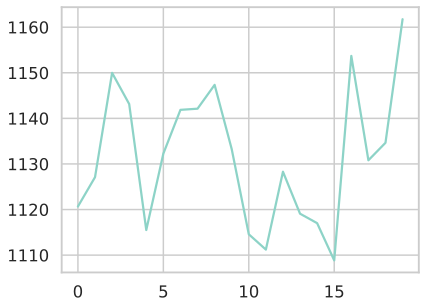

In [ ]:
plt.plot(np.arange(len(inertias)), inertias)

Как мы видим, качество кластеризации сильно зависит от начального приближения

Попробуем инициализацию [с kmeans++:](https://ru.wikipedia.org/wiki/K-means%2B%2B)

In [ ]:
cluster_colors = []
random_cnt = 20
inertias = []

for k in range(random_cnt):
    kmeans = KMeans(n_clusters=5, n_init=1, init='k-means++') # Будем брать 1 итерацию
    kmeans.fit(X_scaled) # Обратите внимание, что обучаемся мы на изначальных, но отшкалированных данных
    cluster_colors.append(kmeans.predict(X_scaled))
    inertias.append(kmeans.inertia_)

In [ ]:
show_slider(X_reduced, cluster_colors, np.arange(1, random_cnt + 1), "Random iteration: ")

In [ ]:
np.std(inertias)

np.float64(9.547005760760914)

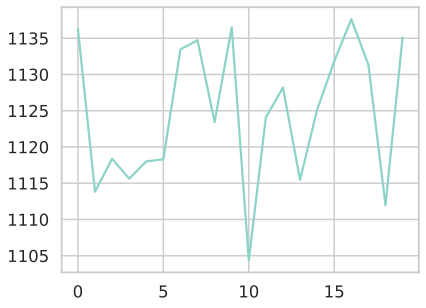

In [ ]:
plt.plot(np.arange(len(inertias)), inertias)

График и значения std инерций стали чуть более устойчивыми

##### Выберем оптимальный k по метрике качества кластеризации

Будем использовать silhouette_score

In [ ]:
from sklearn.metrics import silhouette_score

In [ ]:
silhouette_score?

In [ ]:
scores = []
K = [2, 3] + list(range(4, 30, 2))

for k in tqdm.tqdm(K):
    kmeans = KMeans(n_clusters=k, n_init=10)
    kmeans.fit(X_scaled) # Обратите внимание, что обучаемся мы на изначальных, но отшкалированных данных
    scores.append(silhouette_score(X_scaled, labels=kmeans.predict(X_scaled)))

100%|██████████| 15/15 [00:00<00:00, 24.84it/s]


In [ ]:
df = pd.DataFrame()
df["k"] = K
df["silhouette_score"] = scores

px.line(df, x="k", y="silhouette_score")

#### Agglomerative

##### Разные типы linkage

In [ ]:
# https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html#sphx-glr-auto-examples-cluster-plot-agglomerative-dendrogram-py

from scipy.cluster.hierarchy import dendrogram

from sklearn.cluster import AgglomerativeClustering

def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

In [ ]:
from sklearn.cluster import AgglomerativeClustering

In [ ]:
AgglomerativeClustering?

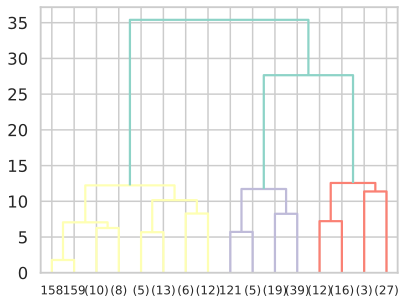

In [ ]:
agg = AgglomerativeClustering(linkage='ward', distance_threshold=0, n_clusters=None)
agg.fit(X_scaled)
plot_dendrogram(agg, truncate_mode="level", p=3)

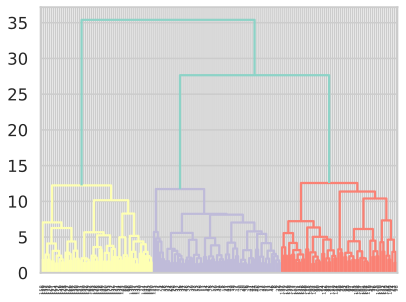

In [ ]:
plot_dendrogram(agg, truncate_mode="level")

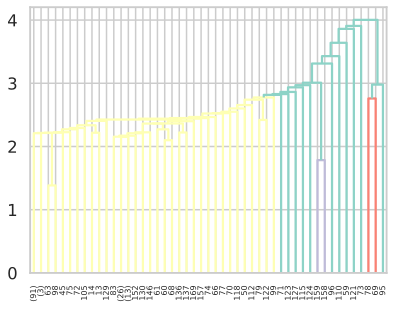

In [ ]:
agg = AgglomerativeClustering(linkage='single', distance_threshold=0, n_clusters=None)
agg.fit(X_scaled)
plot_dendrogram(agg, truncate_mode="level")

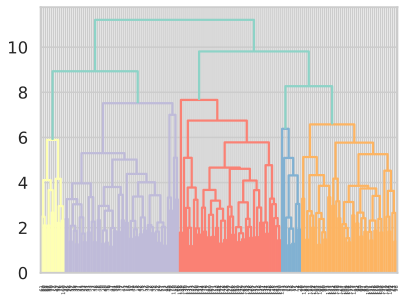

In [ ]:
agg = AgglomerativeClustering(linkage='complete', distance_threshold=0, n_clusters=None)
agg.fit(X_scaled)
plot_dendrogram(agg, truncate_mode="level")

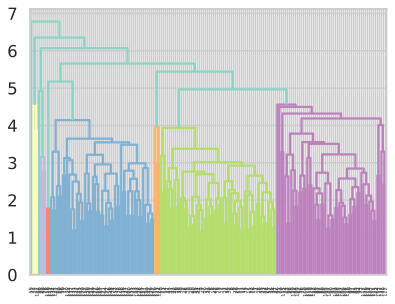

In [ ]:
agg = AgglomerativeClustering(linkage='average', distance_threshold=0, n_clusters=None)
agg.fit(X_scaled)
plot_dendrogram(agg, truncate_mode="level")

#### DBSCAN

Возьмем данные об [общепите в Москве](https://data.mos.ru/opendata?sorting=byNameCatalog-ASC&activeStatus=true&openCategoryIds=115)

In [ ]:
!gdown 1AO1qFJJdu4oqXaXGx2-sIOFbQVNEicHN

Downloading...
From: https://drive.google.com/uc?id=1AO1qFJJdu4oqXaXGx2-sIOFbQVNEicHN
To: /content/data-1903-2024-11-26.csv
100% 12.2M/12.2M [00:00<00:00, 89.4MB/s]


In [ ]:
data = pd.read_csv("/content/data-1903-2024-11-26.csv", sep=';')

In [ ]:
data.head()

,ID,Name,global_id,IsNetObject,OperatingCompany,TypeObject,AdmArea,District,Address,PublicPhone,SeatsCount,SocialPrivileges,Longitude_WGS84,Latitude_WGS84,geoData,geodata_center,Unnamed: 16
0,Код,Наименование,global_id,Является сетевым,Название управляющей компании,Вид объекта,Административный округ по адресу,Район,Адрес,Контактный телефон,Число посадочных мест,Показатель социальных льгот,Долгота в WGS-84,Широта в WGS-84,geoData,geodata_center,NaN
1,00151635,СМЕТАНА,637376221,нет,NaN,кафе,Северо-Восточный административный округ,Ярославский район,"Российская Федерация, город Москва, внутригоро...",nested data,44,нет,37.7145650004360390,55.8790015313033730,"{coordinates=[37.714565, 55.879001531], type=P...","{coordinates=[37.714565, 55.879001531], type=P...",NaN
2,000077874,Родник,637376331,нет,NaN,кафе,Центральный административный округ,Таганский район,"город Москва, улица Талалихина, дом 2/1, корпус 1",nested data,35,нет,37.6733061300344000,55.7382386551547000,"{coordinates=[37.67330613, 55.738238655], type...","{coordinates=[37.67330613, 55.738238655], type...",NaN
3,000024309,Кафе «Академия»,637376349,нет,NaN,ресторан,Центральный административный округ,Таганский район,"Российская Федерация, город Москва, внутригоро...",nested data,95,нет,37.6696475969381000,55.7355114718314000,"{coordinates=[37.669647597, 55.735511472], typ...","{coordinates=[37.669647597, 55.735511472], typ...",NaN
4,000027429,ГБОУ «Школа № 1430 имени Героя Социалистическо...,637376480,нет,NaN,столовая,Северо-Восточный административный округ,район Лианозово,"город Москва, Угличская улица, дом 17",nested data,240,нет,37.5669400000000020,55.9040188006692200,"{coordinates=[37.56694, 55.904018801], type=Po...","{coordinates=[37.56694, 55.904018801], type=Po...",NaN


In [ ]:
data.drop("Unnamed: 16", axis=1, inplace=True)
data.drop(0, axis=0, inplace=True)
data.head()

,ID,Name,global_id,IsNetObject,OperatingCompany,TypeObject,AdmArea,District,Address,PublicPhone,SeatsCount,SocialPrivileges,Longitude_WGS84,Latitude_WGS84,geoData,geodata_center
1,00151635,СМЕТАНА,637376221,нет,NaN,кафе,Северо-Восточный административный округ,Ярославский район,"Российская Федерация, город Москва, внутригоро...",nested data,44,нет,37.7145650004360390,55.8790015313033730,"{coordinates=[37.714565, 55.879001531], type=P...","{coordinates=[37.714565, 55.879001531], type=P..."
2,000077874,Родник,637376331,нет,NaN,кафе,Центральный административный округ,Таганский район,"город Москва, улица Талалихина, дом 2/1, корпус 1",nested data,35,нет,37.6733061300344000,55.7382386551547000,"{coordinates=[37.67330613, 55.738238655], type...","{coordinates=[37.67330613, 55.738238655], type..."
3,000024309,Кафе «Академия»,637376349,нет,NaN,ресторан,Центральный административный округ,Таганский район,"Российская Федерация, город Москва, внутригоро...",nested data,95,нет,37.6696475969381000,55.7355114718314000,"{coordinates=[37.669647597, 55.735511472], typ...","{coordinates=[37.669647597, 55.735511472], typ..."
4,000027429,ГБОУ «Школа № 1430 имени Героя Социалистическо...,637376480,нет,NaN,столовая,Северо-Восточный административный округ,район Лианозово,"город Москва, Угличская улица, дом 17",nested data,240,нет,37.5669400000000020,55.9040188006692200,"{coordinates=[37.56694, 55.904018801], type=Po...","{coordinates=[37.56694, 55.904018801], type=Po..."
5,00148815,Брусника,637376481,да,Брусника,кафе,Центральный административный округ,район Арбат,"город Москва, переулок Сивцев Вражек, дом 6/2",nested data,10,нет,37.5981275484399900,55.7473904905259940,"{coordinates=[37.598127548, 55.747390491], typ...","{coordinates=[37.598127548, 55.747390491], typ..."


In [ ]:
data.shape

(21362, 16)

Почистим данные:

In [ ]:
data.Longitude_WGS84 = data.Longitude_WGS84.astype(float)
data.Latitude_WGS84 = data.Latitude_WGS84.astype(float)

In [ ]:
float("3.12334673781368726348")

3.123346737813687

###### <font color='orange'> **Вопрос 1** </font>
Правильное ли мы сделали преобразование?

In [ ]:
data.head()

,ID,Name,global_id,IsNetObject,OperatingCompany,TypeObject,AdmArea,District,Address,PublicPhone,SeatsCount,SocialPrivileges,Longitude_WGS84,Latitude_WGS84,geoData,geodata_center
1,00151635,СМЕТАНА,637376221,нет,NaN,кафе,Северо-Восточный административный округ,Ярославский район,"Российская Федерация, город Москва, внутригоро...",nested data,44,нет,37.714565,55.879002,"{coordinates=[37.714565, 55.879001531], type=P...","{coordinates=[37.714565, 55.879001531], type=P..."
2,000077874,Родник,637376331,нет,NaN,кафе,Центральный административный округ,Таганский район,"город Москва, улица Талалихина, дом 2/1, корпус 1",nested data,35,нет,37.673306,55.738239,"{coordinates=[37.67330613, 55.738238655], type...","{coordinates=[37.67330613, 55.738238655], type..."
3,000024309,Кафе «Академия»,637376349,нет,NaN,ресторан,Центральный административный округ,Таганский район,"Российская Федерация, город Москва, внутригоро...",nested data,95,нет,37.669648,55.735511,"{coordinates=[37.669647597, 55.735511472], typ...","{coordinates=[37.669647597, 55.735511472], typ..."
4,000027429,ГБОУ «Школа № 1430 имени Героя Социалистическо...,637376480,нет,NaN,столовая,Северо-Восточный административный округ,район Лианозово,"город Москва, Угличская улица, дом 17",nested data,240,нет,37.566940,55.904019,"{coordinates=[37.56694, 55.904018801], type=Po...","{coordinates=[37.56694, 55.904018801], type=Po..."
5,00148815,Брусника,637376481,да,Брусника,кафе,Центральный административный округ,район Арбат,"город Москва, переулок Сивцев Вражек, дом 6/2",nested data,10,нет,37.598128,55.747390,"{coordinates=[37.598127548, 55.747390491], typ...","{coordinates=[37.598127548, 55.747390491], typ..."


In [ ]:
# data.iloc[0, :]["Latitude_WGS84"]

Отобразим данные на карте:

In [ ]:
fig = px.scatter_mapbox(data,
                        lat='Latitude_WGS84',
                        lon='Longitude_WGS84',
                        text='TypeObject',
                        hover_name='Name',
                        zoom=8)
fig.update_layout(mapbox_style="open-street-map")
fig.show()

Попробуем найти торговые центры. Предположение - в торговых центрах наиболее плотное скопление точек с едой, чем вне торговых центров

In [ ]:
from sklearn.cluster import DBSCAN

###### <font color='orange'> **Задание** </font>
Подберите параметры eps и min_samples, визуально оценивания получившиеся кластеризации. Визуализация есть ниже

In [ ]:
data.describe()

,Longitude_WGS84,Latitude_WGS84
count,21362.000000,21362.000000
mean,37.586348,55.741142
std,0.124772,0.090070
min,36.862404,55.212892
25%,37.520707,55.687226
50%,37.598373,55.751076
75%,37.656360,55.792817
max,37.948016,56.016275


In [ ]:
DBSCAN?

In [ ]:
dbscan = DBSCAN(eps=0.0000000001,
                min_samples=100,

)

dbscan.fit(data[["Latitude_WGS84", "Longitude_WGS84"]])

DBSCAN(eps=1e-10, min_samples=100)

In [ ]:
colors = dbscan.labels_ # -1 это шумовые объекты
colors[colors != -1] = 1
colors[colors == -1] = 0

data["colors"] = colors

In [ ]:
fig = px.scatter_mapbox(data[data.colors == 0],
                        lat='Latitude_WGS84',
                        lon='Longitude_WGS84',
                        text='TypeObject',
                        hover_name='Name',
                        zoom=8)

fig2 = px.scatter_mapbox(data[data.colors == 1],
                        lat='Latitude_WGS84',
                        lon='Longitude_WGS84',
                        text='TypeObject',
                        hover_name='Name',
                        zoom=8)
fig2.update_traces(cluster=dict(enabled=True, step=3, opacity=1))


fig.add_trace(fig2._data[0])
fig.data[0].marker.color = 'rgba(255,0,0,1)'


fig.update_layout(mapbox_style="open-street-map")
fig.show()